# Customer Churn Prediction (Logistic Regression)

Binary classification of telecom customer churn with logistic regression on standardized features, evaluated with log loss, plus interpretation of the coefficients.


In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/ChurnData.csv"
churn_df = pd.read_csv(url)
churn_df = churn_df[['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip', 'churn']]
churn_df['churn'] = churn_df['churn'].astype('int')

X = np.asarray(churn_df[['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip']])
y = np.asarray(churn_df['churn'])
X_norm = StandardScaler().fit(X).transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.2, random_state=4)

LR = LogisticRegression().fit(X_train, y_train)
y_pred = LR.predict(X_test)
y_pred_prob = LR.predict_proba(X_test)

print("Log Loss: %.2f" % log_loss(y_test, y_pred_prob))


Log Loss: 0.63


In [48]:
yhat_prob = LR.predict_proba(X_test)
yhat_prob[:10]

array([[0.74643946, 0.25356054],
       [0.92667894, 0.07332106],
       [0.83442627, 0.16557373],
       [0.94600618, 0.05399382],
       [0.84325532, 0.15674468],
       [0.71448367, 0.28551633],
       [0.77076426, 0.22923574],
       [0.90955642, 0.09044358],
       [0.26152115, 0.73847885],
       [0.94900731, 0.05099269]])

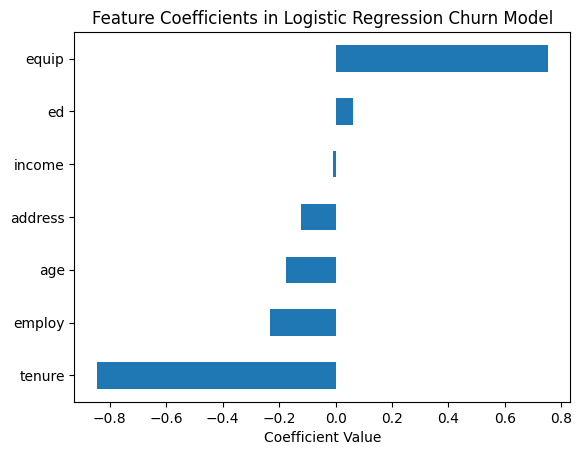

In [49]:
coefficients = pd.Series(LR.coef_[0], index=churn_df.columns[:-1])
coefficients.sort_values().plot(kind='barh')
plt.title("Feature Coefficients in Logistic Regression Churn Model")
plt.xlabel("Coefficient Value")
plt.show()

Tenure and equipment rental are the two dominant drivers of churn, and they push in opposite directions.

Tenure (≈ −0.85) is the strongest factor, and it lowers churn. The longer someone has been a customer, the less likely they are to leave. One standard deviation more tenure cuts the odds of churn by about 57% (e^−0.85 ≈ 0.43).
Equip (≈ +0.75) is the strongest factor that raises churn. Customers who rent equipment have about 2.1× higher odds of churning (e^0.75 ≈ 2.1). This is a risk group worth targeting.
Stability factors lower churn moderately. Years with their current employer (employ ≈ −0.24), age (≈ −0.18) and years at their current address (address ≈ −0.12) all reduce churn. Older, more settled customers tend to stay.
Education (≈ +0.06) and income (≈ −0.01) have almost no effect. They contribute little to the model's predictions and could likely be dropped without hurting accuracy.
Takeaway
Churn risk is concentrated among new customers who rent equipment. Retention efforts work best early in the customer relationship, such as onboarding incentives or loyalty discounts in the first months. A second lever is the equipment offer, for example converting rentals into purchase or bundled plans.